Class distribution:
Disease
0    12064
1     6189
Name: count, dtype: int64
Disease Cases: 6189 (33.9%)

Logistic Regression Results:
 Accuracy: 0.752
 Precision: 0.610
 Recall: 0.743
 F1-Score: 0.670

Decision Tree Results:
 Accuracy: 0.769
 Precision: 0.629
 Recall: 0.776
 F1-Score: 0.695
Confusion Matrix: [[1845  568]
 [ 277  961]]


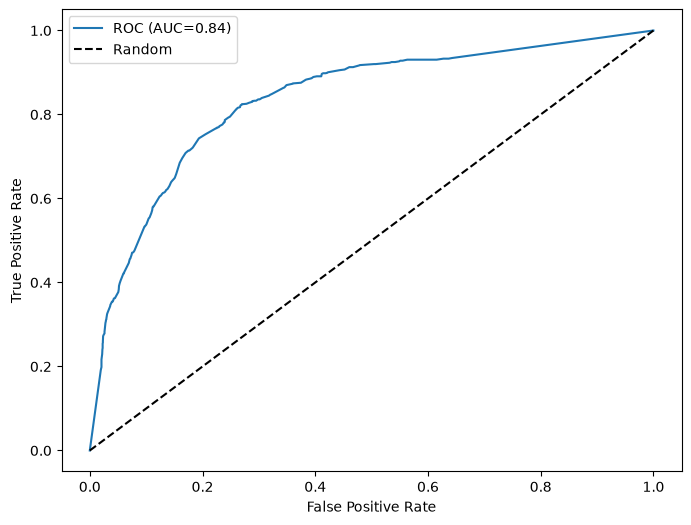

AUC: 0.835


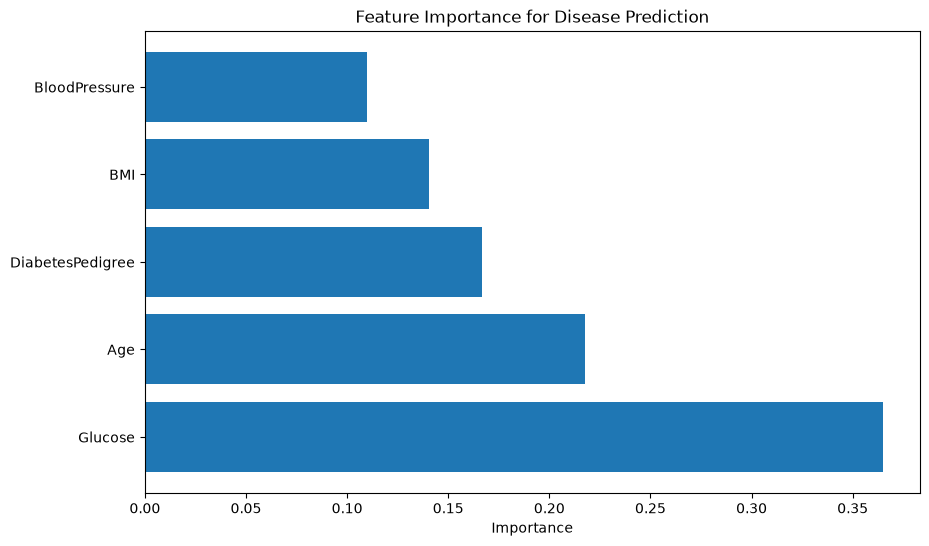

Disease likely (Probability: 50.4%)
DISEASE PREDICTION MODEL REPORT
Dataset Size: 18253
Disease Cases: 6189
Healthy Cases: 12064

Logistic Regression Acc: 75.2%, Prec: 61.0%, Recall: 74.3%, F1: 0.670
Decision Tree Acc: 76.9%, Prec: 62.9%, Recall: 77.6%, F1: 0.695

Best Model: Decision Tree

Top 3 Important Features:
         Feature  Importance
         Glucose    0.364985
             Age    0.217726
DiabetesPedigree    0.166806


In [2]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc)
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

data = pd.read_csv('disease_data_large_v2.csv')
data = data.dropna()
X = data.drop('Disease', axis=1)
y = data['Disease']

print(f"Class distribution:\n{y.value_counts()}")
print(f"Disease Cases: {sum(y)} ({y.mean():.1%})")

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaler = scaler.fit_transform(X_train)
X_valid_scaler = scaler.transform(X_valid)

logReg = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
X_train_scaler, y_train_sm = smote.fit_resample(X_train_scaler, y_train)
logReg.fit(X_train_scaler, y_train_sm)
logPredictions = logReg.predict(X_valid_scaler)
logAccuracy = accuracy_score(y_valid, logPredictions)
logPrecision = precision_score(y_valid, logPredictions)
logRecall = recall_score(y_valid, logPredictions)
logF1 = f1_score(y_valid, logPredictions)
print(f"\nLogistic Regression Results:")
print(f" Accuracy: {logAccuracy:.3f}")
print(f" Precision: {logPrecision:.3f}")
print(f" Recall: {logRecall:.3f}")
print(f" F1-Score: {logF1:.3f}")

decTreeMod = DecisionTreeClassifier(max_depth=10, random_state=42, class_weight='balanced')
decTreeMod.fit(X_train, y_train)
decTreeModPredictions = decTreeMod.predict(X_valid)
decTreeModAccuracy = accuracy_score(y_valid, decTreeModPredictions)
decTreeModPrecision = precision_score(y_valid, decTreeModPredictions)
decTreeModRecall = recall_score(y_valid, decTreeModPredictions)
decTreeModF1 = f1_score(y_valid, decTreeModPredictions)
print(f"\nDecision Tree Results:")
print(f" Accuracy: {decTreeModAccuracy:.3f}")
print(f" Precision: {decTreeModPrecision:.3f}")
print(f" Recall: {decTreeModRecall:.3f}")
print(f" F1-Score: {decTreeModF1:.3f}")

confusionMatrix = confusion_matrix(y_valid, decTreeModPredictions)
print(f"Confusion Matrix: {confusionMatrix}")

yPredictProbab = decTreeMod.predict_proba(X_valid)[:, 1]
fpr, tpr, _ = roc_curve(y_valid, yPredictProbab)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC (AUC={roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()
print(f"AUC: {roc_auc:.3f}")

importance = decTreeMod.feature_importances_
featureNames = X.columns
importanceDF = pd.DataFrame({
    'Feature': featureNames,
    'Importance': importance
}).sort_values('Importance', ascending=False)
plt.figure(figsize=(10, 6))
plt.barh(importanceDF['Feature'], importanceDF['Importance'])
plt.xlabel('Importance')
plt.title('Feature Importance for Disease Prediction')
plt.show()

newPatient = pd.DataFrame({
    'Age': [33],
    'BloodPressure': [140],
    'Glucose': [110],
    'BMI': [25],
    'DiabetesPedigree': [0.42]
})
predictions = decTreeMod.predict(newPatient)
probability = decTreeMod.predict_proba(newPatient)[0, 1]
if predictions[0] == 1:
    print(f'Disease likely (Probability: {probability:.1%})')
else:
    print(f'No Disease (Probability: {probability:.1%})')

print("DISEASE PREDICTION MODEL REPORT")
print(f"Dataset Size: {len(data)}")
print(f"Disease Cases: {sum(y)}")
print(f"Healthy Cases: {len(y) - sum(y)}")

print(f"\nLogistic Regression Acc: {logAccuracy:.1%}, Prec: {logPrecision:.1%}, "
      f"Recall: {logRecall:.1%}, F1: {logF1:.3f}")
print(f"Decision Tree Acc: {decTreeModAccuracy:.1%}, Prec: {decTreeModPrecision:.1%}, "
      f"Recall: {decTreeModRecall:.1%}, F1: {decTreeModF1:.3f}")

best_model = "Decision Tree" if decTreeModF1 >= logF1 else "Logistic Regression"
print(f"\nBest Model: {best_model}")

print(f"\nTop 3 Important Features:")
print(importanceDF.head(3).to_string(index=False))